# 12. The classical price

DMRG finds ground states as matrix product states (MPS). Its cost is set by one number, the bond dimension
$\chi$, and that number is set by entanglement. This notebook measures how big $\chi$ must be to get the
ground-state energy of the J1-J2 model to $\epsilon = 0.01$, and what that costs, as the cylinder gets wider.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dmrg_from_scratch import ground_state, j1j2_cylinder
from dmrg_from_scratch.resources import (
    best_energy,
    classical_cost,
    fit_line,
    load_ladders,
    reference_energy,
    run_ladder,
)

## 1. Why width is the enemy: the area law

An MPS with bond dimension $\chi$ can carry at most $S = \log_2\chi$ bits of entanglement across any cut. On a cylinder
the cut that splits it into a left and a right half crosses $W$ bonds, and a gapped or ordered ground state has
$S \approx aW$ (an area law). So the bond dimension needed grows like $\chi \sim 2^{aW}$, and since DMRG costs
$\propto \chi^3$, the time grows like $2^{3aW}$. Making the cylinder *longer* is cheap (linear); making it
*wider* is exponential.

The MPS walks through the cylinder column by column ($s = xW + y$), so a spin's right-hand neighbour is $W$
steps away along the chain.

## 2. A live run: error against bond dimension

The 4 x 4 cylinder (16 spins) is small enough for exact diagonalization, so we can watch the DMRG error fall as
$\chi$ grows. Each rung starts from the previous one.

In [2]:
H = j1j2_cylinder(4)  # 4 x 4 cylinder, J2/J1 = 0.5
E0, _ = ground_state(H)
live = run_ladder(H, chis=(2, 4, 8, 16), n_sweeps=3)
for r in live:
    print(f"chi = {r['chi']:3d}   E - E0 = {r['energy'] - E0:.2e}   S = {r['entropy']:.3f}   {r['seconds']:.1f} s")

chi =   2   E - E0 = 1.58e+00   S = 0.077   0.1 s
chi =   4   E - E0 = 2.06e-01   S = 0.072   0.1 s
chi =   8   E - E0 = 9.31e-02   S = 0.374   0.2 s
chi =  16   E - E0 = 6.89e-03   S = 0.554   0.2 s


## 3. The full runs, widths 3 to 8

Precomputed with `python scripts/make_results.py` (about half an hour, set by the 8 x 8 cylinder). For
widths 3 and 4 the error is measured against exact diagonalization. For the wider ones the exact energy is
unknown; we use the standard trick of extrapolating $E(\chi)$ linearly in the discarded weight to zero
[White and Chernyshev, [arXiv:0705.2746](https://arxiv.org/abs/0705.2746)]. At $W = 4$ this extrapolation agrees
with exact diagonalization to $10^{-5}$:

In [3]:
ladders = load_ladders()
lad4 = next(lad for lad in ladders if lad["W"] == 4)
print("extrapolated:", reference_energy([r for r in lad4["runs"] if r["discarded"] > 0]))
print("exact       :", lad4["exact_energy"])

extrapolated: -8.261241836138192
exact       : -8.261232563029774


Odd widths are shown in grey. On an odd-circumference cylinder the antiferromagnetic (Néel) pattern cannot
close around the cylinder, which makes the state far more entangled: it is a different problem, so we only use
even widths for the scaling.

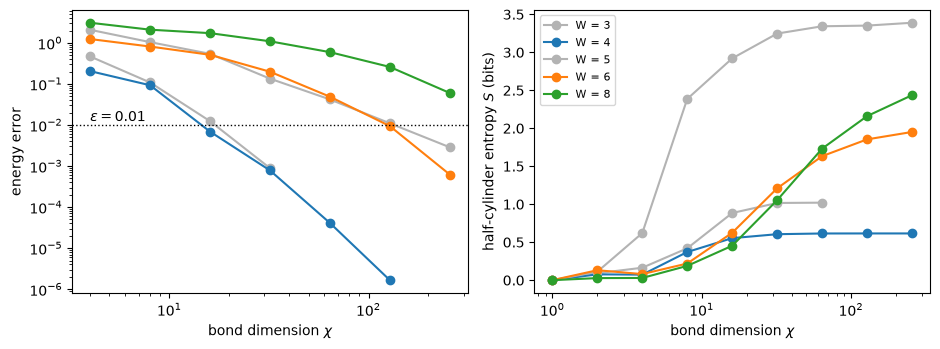

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
for lad in ladders:
    E_ref = best_energy(lad)
    runs = [r for r in lad["runs"] if r["energy"] - E_ref > 1e-9 and r["chi"] >= 4]
    style = dict(color="0.7") if lad["W"] % 2 else {}
    ax[0].loglog([r["chi"] for r in runs], [r["energy"] - E_ref for r in runs], "o-", label=f"W = {lad['W']}", **style)
    chis, S = [r["chi"] for r in lad["runs"]], [r["entropy"] for r in lad["runs"]]
    ax[1].semilogx(chis, S, "o-", label=f"W = {lad['W']}", **style)
ax[0].axhline(0.01, color="k", ls=":", lw=1)
ax[0].text(4, 0.012, r"$\epsilon = 0.01$")
ax[0].set(xlabel=r"bond dimension $\chi$", ylabel="energy error")
ax[1].set(xlabel=r"bond dimension $\chi$", ylabel="half-cylinder entropy $S$ (bits)")
ax[1].legend(fontsize=8)
fig.tight_layout()

Two things to read off. The error falls roughly as a power law in $\chi$, more slowly for wider cylinders. And
the entropy saturates at a value that grows with $W$ (for even $W$): that saturated value is the entanglement DMRG has to pay
for. At $W = 8$ it is still rising at $\chi = 256$, a sign that this cylinder is not fully converged.

## 4. Bond dimension needed for $\epsilon = 0.01$

Fit $E(\chi) - E_\text{ref} = A\chi^{-b}$ on the three largest $\chi$ and solve for $\epsilon$:

In [5]:
even = [lad for lad in ladders if lad["W"] % 2 == 0]
costs = [classical_cost(lad, eps=0.01) for lad in even]
for c in costs:
    print(f"W = {c['W']}   N = {c['n']:3d}   chi needed = {c['chi']:7.0f}")

W = 4   N =  16   chi needed =      18
W = 6   N =  36   chi needed =     112
W = 8   N =  64   chi needed =     808


## 5. From bond dimension to seconds

DMRG spends its time applying the effective Hamiltonian to the two-site tensor, $\approx 4 w d^2 \chi^3$ flops per
Lanczos step ($w$ is the MPO bond dimension, $d = 2$). Our DMRG counts its own flops; per sweep they grow as
$\chi^3$:

In [6]:
lad6 = next(lad for lad in ladders if lad["W"] == 6)
chis = np.array([r["chi"] for r in lad6["runs"]])[4:]
flops = np.array([r["flops_per_sweep"] for r in lad6["runs"]])[4:]
print("slope of log(flops) vs log(chi):", round(np.polyfit(np.log(chis), np.log(flops), 1)[0], 2))
rate = sum(r["flops_per_sweep"] * 3 for r in lad6["runs"]) / sum(r["seconds"] for r in lad6["runs"])
print(f"the runs in results/ went at about {rate / 1e9:.0f} GFLOP/s")

slope of log(flops) vs log(chi): 2.99
the runs in results/ went at about 37 GFLOP/s


A serious DMRG code on a large node or GPU sustains more like $10^{12}$ to $10^{13}$ flop/s, and it uses the
SU(2) spin symmetry, which shrinks the effective $\chi$ a lot. We take 10 sweeps at $10^{12}$ flop/s as the
reference machine and carry a factor 10 either way. The width dependence is what matters:

cost grows by a factor 33 per unit of width


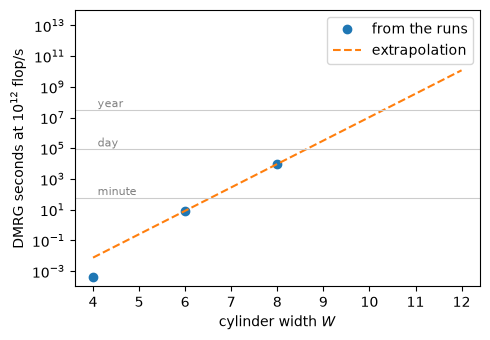

In [7]:
W = np.array([c["W"] for c in costs])
sec = np.array([c["seconds"] for c in costs])
a, b = fit_line(W[1:], np.log(sec[1:]))  # fit on W = 6, 8
print(f"cost grows by a factor {np.exp(b):.0f} per unit of width")

Wx = np.linspace(4, 12, 50)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(W, sec, "o", label="from the runs")
ax.semilogy(Wx, np.exp(a + b * Wx), "--", label="extrapolation")
for t, lab in [(60, "minute"), (3600 * 24, "day"), (3600 * 24 * 365, "year")]:
    ax.axhline(t, color="0.8", lw=0.8)
    ax.text(4.1, t * 1.5, lab, color="0.5", fontsize=8)
ax.set(xlabel="cylinder width $W$", ylabel="DMRG seconds at $10^{12}$ flop/s", ylim=(1e-4, 1e14))
ax.legend()
fig.tight_layout()

An 8 x 8 cylinder takes a couple of hours; a 12 x 12 one would take centuries. This is
the exponential wall that a quantum computer is supposed to get around. Notebook 13 prices the quantum route.

## Exercises

1. Change $\epsilon$ to 0.1 and to 0.001. How does $\chi$ needed respond at $W = 8$, and why is the power-law
   exponent $b$ the thing that decides it?
2. Rerun `run_ladder` on the 4 x 4 cylinder with `J2=0`. Is the unfrustrated model cheaper for DMRG?
3. The 8 x 8 runs use only 3 sweeps per $\chi$. Edit `scripts/make_results.py` to use more and see how much
   the extrapolated energy and the $\chi$ needed move.
4. Include $W = 4$ in the fit of section 5. How much does the extrapolation to $W = 12$ change? What does that
   tell you about trusting it?